# EDA: rendimiento académico en matemáticas

## 1. Introducción
La institución desea conocer qué factores se relacionan con el rendimiento de sus estudiantes en matemáticas. En este análisis exploramos los puntajes y su relación con las horas de estudio, la educación de los padres, el acceso a internet y las actividades extracurriculares.

El objetivo es conocer los datos y encontrar patrones que ayuden a orientar el acompañamiento académico. **Este notebook no incluye modelos ni predicciones.**

**Nota:** el CSV no está incluido en el notebook original. Es necesario cargarlo para obtener los resultados. Las salidas guardadas en el original mostraban más de ocho millones de filas; se debe verificar que ese dataset corresponda al proyecto.

**Salidas en español:** se traducen los títulos, etiquetas y encabezados de las tablas sin modificar los nombres originales de las columnas. Los valores de las categorías y los códigos se conservan para no interpretar su significado sin el diccionario de datos. Las salidas aparecerán al ejecutar las celdas con el CSV real.

## 2. Importar librerías
Usaremos pandas para trabajar con los datos y matplotlib y seaborn para crear gráficos.

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
from IPython.display import display

# Estos nombres solo cambian lo que mostramos, no las columnas del dataset.
nombres_es = {
    "Age": "Edad", "Grade": "Grado escolar", "Gender": "Género",
    "Race": "Grupo étnico (según fuente)", "SES_Quartile": "Cuartil socioeconómico",
    "ParentalEducation": "Educación de los padres", "SchoolType": "Tipo de escuela",
    "Locale": "Zona de residencia", "TestScore_Math": "Puntaje de matemáticas",
    "TestScore_Reading": "Puntaje de lectura", "TestScore_Science": "Puntaje de ciencias",
    "GPA": "Promedio académico (GPA)", "AttendanceRate": "Tasa de asistencia",
    "StudyHours": "Tiempo de estudio (unidad por confirmar)", "InternetAccess": "Acceso a internet",
    "Extracurricular": "Participación extracurricular", "PartTimeJob": "Trabajo a tiempo parcial",
    "ParentSupport": "Apoyo parental", "Romantic": "Relación sentimental (según fuente)",
    "FreeTime": "Tiempo libre", "GoOut": "Salidas sociales"
}
estadisticas_es = {
    "count": "Puntajes válidos", "mean": "Promedio", "median": "Mediana",
    "std": "Desviación estándar", "min": "Mínimo", "max": "Máximo",
    "25%": "Percentil 25", "50%": "Mediana", "75%": "Percentil 75"
}

## 3. Cargar el dataset
Sube el CSV y cambia la ruta si tiene otro nombre o ubicación.

In [29]:
# En Kaggle, la ruta del notebook original era:
# "/kaggle/input/student-performance/train.csv"
df = pd.read_csv("../data/raw/train.csv")

# Mostrar las primeras cinco filas
display(df.head().rename(columns=nombres_es))

,Edad,Grado escolar,Género,Grupo étnico (según fuente),Cuartil socioeconómico,Educación de los padres,Tipo de escuela,Zona de residencia,Puntaje de matemáticas,Puntaje de lectura,...,Promedio académico (GPA),Tasa de asistencia,Tiempo de estudio (unidad por confirmar),Acceso a internet,Participación extracurricular,Trabajo a tiempo parcial,Apoyo parental,Relación sentimental (según fuente),Tiempo libre,Salidas sociales
0,17,12,Female,White,3,HS,Public,Suburban,70.258235,79.665185,...,2.743879,0.906809,1.089243,1,1,0,0,0,2,2
1,18,12,Female,White,2,HS,Public,Suburban,67.876546,59.611505,...,2.587700,0.843739,0.879911,1,1,0,1,0,5,2
2,16,11,Female,White,2,HS,Public,City,62.070623,70.577443,...,2.426294,0.850923,1.003442,1,1,0,1,1,5,1
3,14,9,Female,White,4,Bachelors+,Public,Town,79.909312,82.924450,...,3.558240,0.946786,1.814810,1,1,0,1,0,4,2
4,16,11,Female,Two-or-more,4,SomeCollege,Public,Rural,90.562294,95.352336,...,3.896884,0.988036,1.157241,1,1,0,0,0,3,4


## 4. Conocer los datos
Revisamos cuántos registros hay, qué columnas contiene el dataset y cuáles son sus tipos de datos.

In [30]:
print("Cantidad de registros:", df.shape[0])
print("Cantidad de variables:", df.shape[1])

estructura = pd.DataFrame({
    "Variable original": df.columns,
    "Nombre en español": [nombres_es.get(c, c) for c in df.columns],
    "Tipo de dato": df.dtypes.astype(str).values
})
display(estructura)

Cantidad de registros: 8000774
Cantidad de variables: 21


,Variable original,Nombre en español,Tipo de dato
0,Age,Edad,int64
1,Grade,Grado escolar,int64
2,Gender,Género,str
3,Race,Grupo étnico (según fuente),str
4,SES_Quartile,Cuartil socioeconómico,int64
5,ParentalEducation,Educación de los padres,str
6,SchoolType,Tipo de escuela,str
7,Locale,Zona de residencia,str
8,TestScore_Math,Puntaje de matemáticas,float64
9,TestScore_Reading,Puntaje de lectura,float64


La siguiente tabla resume las variables numéricas: cantidad de valores, media, desviación, mínimo, máximo y cuartiles.

In [31]:
display(df.describe().T.rename(index=nombres_es, columns=estadisticas_es).round(2))

,Puntajes válidos,Promedio,Desviación estándar,Mínimo,Percentil 25,Mediana,Percentil 75,Máximo
Edad,8000774.0,16.00,1.41,14.00,15.00,16.0,17.00,18.00
Grado escolar,8000774.0,10.80,1.17,9.00,10.00,11.0,12.00,12.00
Cuartil socioeconómico,8000774.0,2.50,1.12,1.00,1.00,3.0,3.00,4.00
Puntaje de matemáticas,8000774.0,74.98,9.94,22.58,68.25,75.0,81.74,100.00
Puntaje de lectura,8000774.0,74.98,9.94,21.19,68.25,75.0,81.74,100.00
Puntaje de ciencias,8000774.0,74.98,9.95,19.19,68.26,75.0,81.74,100.00
Promedio académico (GPA),8000774.0,3.00,0.46,0.71,2.69,3.0,3.31,4.00
Tasa de asistencia,8000774.0,0.90,0.05,0.70,0.87,0.9,0.93,1.00
Tiempo de estudio (unidad por confirmar),8000774.0,1.00,0.35,0.00,0.76,1.0,1.24,2.79
Acceso a internet,8000774.0,0.85,0.36,0.00,1.00,1.0,1.00,1.00


## 5. Revisar la calidad de los datos
Buscamos valores faltantes y filas repetidas. No eliminamos ni completamos datos automáticamente: primero debemos entender por qué aparecen.

In [32]:
faltantes = pd.DataFrame({
    "Datos faltantes": df.isnull().sum(),
    "Porcentaje faltante (%)": df.isnull().mean() * 100
}).rename(index=nombres_es)
display(faltantes.round(2))
print("Total de celdas faltantes:", int(df.isnull().sum().sum()))

,Datos faltantes,Porcentaje faltante (%)
Edad,0,0.0
Grado escolar,0,0.0
Género,0,0.0
Grupo étnico (según fuente),0,0.0
Cuartil socioeconómico,0,0.0
Educación de los padres,0,0.0
Tipo de escuela,0,0.0
Zona de residencia,0,0.0
Puntaje de matemáticas,0,0.0
Puntaje de lectura,0,0.0


Total de celdas faltantes: 0


In [33]:
repetidos = df.duplicated().sum()
print("Filas idénticas a una anterior:", repetidos)
print("Porcentaje de filas repetidas:", round(repetidos / len(df) * 100, 2), "%")
print("No se eliminan automáticamente: primero hay que verificar si son errores.")

Filas idénticas a una anterior: 0
Porcentaje de filas repetidas: 0.0 %
No se eliminan automáticamente: primero hay que verificar si son errores.


**Cómo interpretar:** si una columna tiene faltantes, habrá que decidir cómo tratarlos en la preparación del modelo. Dos filas iguales no necesariamente son el mismo estudiante; por eso no se borran sin revisar.

## 6. Distribución del puntaje de matemáticas
`TestScore_Math` es la variable principal. El histograma muestra cómo se distribuyen los puntajes y el diagrama de caja permite observar su dispersión y posibles valores extremos.

Para que los gráficos no sean lentos si el archivo es grande, utilizamos una muestra aleatoria de hasta 10.000 filas. Las tablas y medias se calculan con todos los registros.

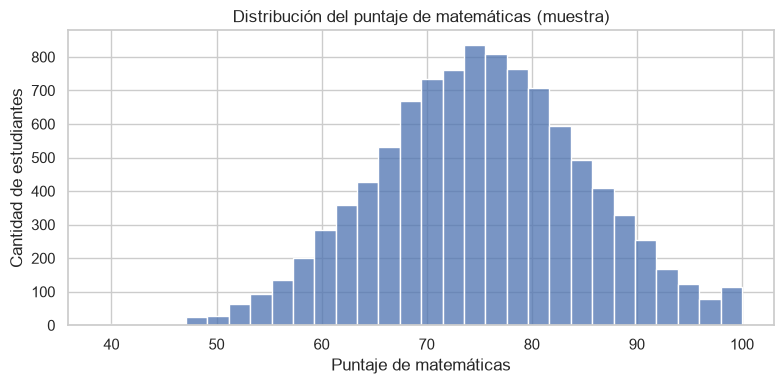

Media: 74.98
Mediana: 75.0
Puntaje mínimo: 22.58
Puntaje máximo: 100.0
Desviación estándar: 9.94
Puntajes disponibles: 8000774


In [34]:
datos_graficos = df.sample(n=min(10000, len(df)), random_state=42)

plt.figure(figsize=(8, 4))
sns.histplot(data=datos_graficos, x="TestScore_Math", bins=30)
plt.title("Distribución del puntaje de matemáticas (muestra)")
plt.xlabel("Puntaje de matemáticas")
plt.ylabel("Cantidad de estudiantes")
plt.tight_layout()
plt.show()

print("Media:", round(df["TestScore_Math"].mean(), 2))
print("Mediana:", round(df["TestScore_Math"].median(), 2))
print("Puntaje mínimo:", round(df["TestScore_Math"].min(), 2))
print("Puntaje máximo:", round(df["TestScore_Math"].max(), 2))
print("Desviación estándar:", round(df["TestScore_Math"].std(), 2))
print("Puntajes disponibles:", df["TestScore_Math"].count())

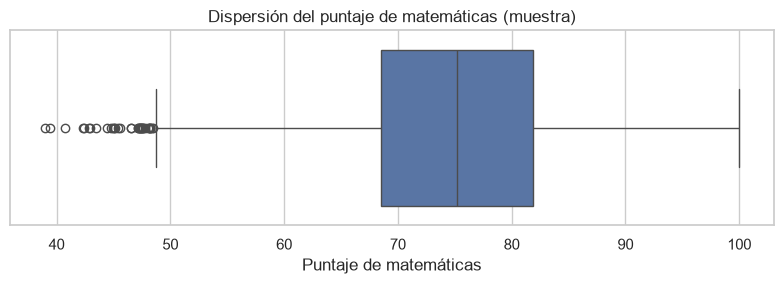

In [35]:
plt.figure(figsize=(8, 3))
sns.boxplot(data=datos_graficos, x="TestScore_Math")
plt.title("Dispersión del puntaje de matemáticas (muestra)")
plt.xlabel("Puntaje de matemáticas")
plt.tight_layout()
plt.show()

**Para interpretar:** observa dónde se concentra la mayor cantidad de puntajes y si existen resultados alejados del resto. Un puntaje extremo no necesariamente es un error.

No se crean clases “bajo”, “medio” o “alto” porque no tenemos un criterio institucional para definirlas. El puntaje es una variable numérica continua.

## 7. Analizar las categorías del dataset
Contamos los estudiantes según educación parental, acceso a internet y participación en actividades extracurriculares. Los códigos se mantienen como aparecen en el archivo: confirma su significado con el diccionario de datos.

,Cantidad de registros,Porcentaje (%)
Educación de los padres,,
HS,2601118,32.51
SomeCollege,2400823,30.01
Bachelors+,1500310,18.75
<HS,1498523,18.73


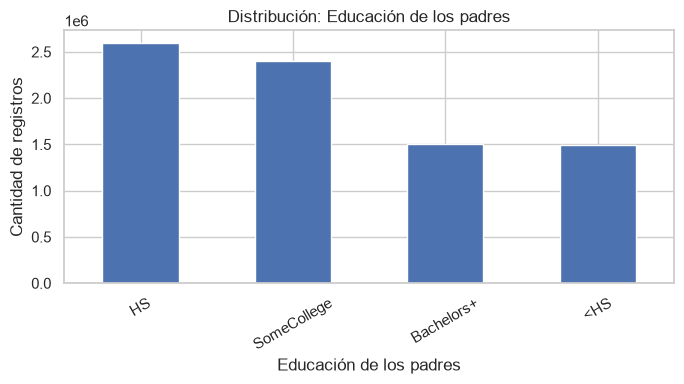

,Cantidad de registros,Porcentaje (%)
Acceso a internet,,
1,6799271,84.98
0,1201503,15.02


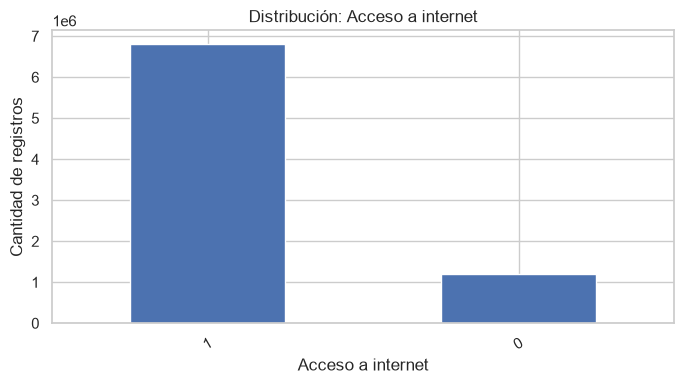

,Cantidad de registros,Porcentaje (%)
Participación extracurricular,,
1,4400178,55.0
0,3600596,45.0


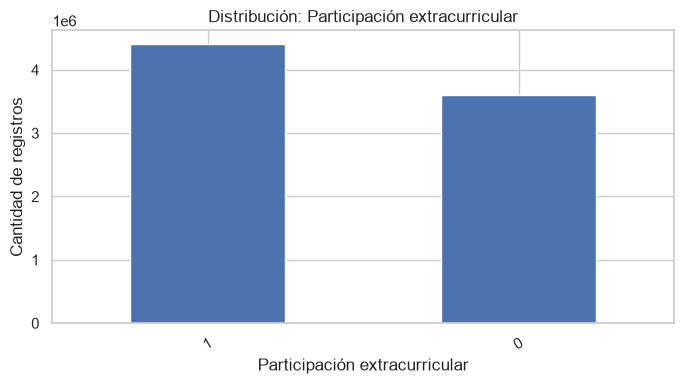

In [36]:
columnas = ["ParentalEducation", "InternetAccess", "Extracurricular"]

for columna in columnas:
    conteos = df[columna].value_counts(dropna=False)
    tabla = pd.DataFrame({"Cantidad de registros": conteos,
                          "Porcentaje (%)": conteos / len(df) * 100})
    tabla.index.name = nombres_es[columna]
    display(tabla.round(2))

    conteos.plot(kind="bar", figsize=(7, 4))
    plt.title("Distribución: " + nombres_es[columna])
    plt.xlabel(nombres_es[columna])
    plt.ylabel("Cantidad de registros")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

## 8. Educación de los padres y matemáticas
Comparamos los puntajes según el nivel educativo de los padres. La tabla muestra cuántos puntajes válidos hay en cada grupo, su media y su mediana.

In [37]:
resumen_padres = df.groupby("ParentalEducation")["TestScore_Math"].agg(["count", "mean", "median", "std"])
display(resumen_padres.rename(columns=estadisticas_es).rename_axis("Educación de los padres").round(2))

,Puntajes válidos,Promedio,Mediana,Desviación estándar
Educación de los padres,,,,
<HS,1498523,74.95,74.97,9.95
Bachelors+,1500310,74.99,75.01,9.94
HS,2601118,74.99,75.00,9.94
SomeCollege,2400823,74.96,74.99,9.95


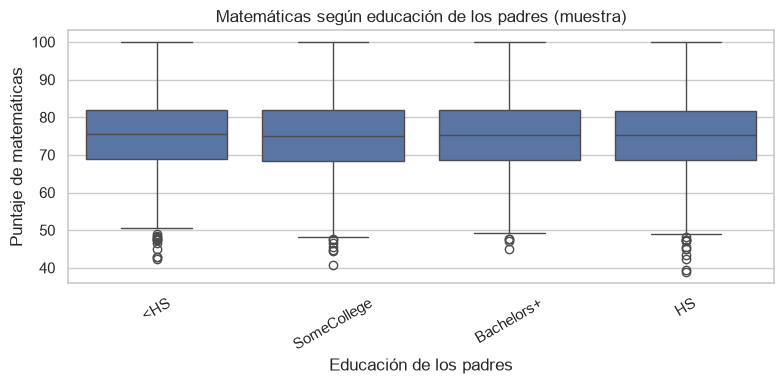

In [38]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=datos_graficos, x="ParentalEducation", y="TestScore_Math")
plt.title("Matemáticas según educación de los padres (muestra)")
plt.xlabel("Educación de los padres")
plt.ylabel("Puntaje de matemáticas")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 9. Acceso a internet y matemáticas
Comparamos el promedio del puntaje entre las categorías de acceso a internet. El gráfico usa todos los registros con categoría y puntaje disponibles.

,Puntajes válidos,Promedio,Mediana,Desviación estándar
Acceso a internet,,,,
0,1201503,74.97,74.98,9.95
1,6799271,74.98,75.00,9.94


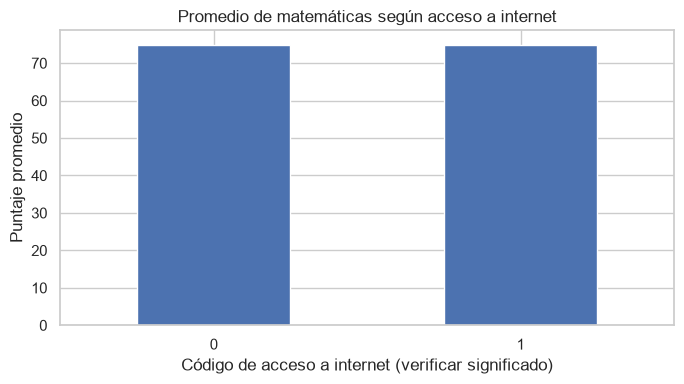

In [39]:
resumen_internet = df.groupby("InternetAccess")["TestScore_Math"].agg(["count", "mean", "median", "std"])
display(resumen_internet.rename(columns=estadisticas_es).rename_axis("Acceso a internet").round(2))

resumen_internet["mean"].plot(kind="bar", figsize=(7, 4))
plt.title("Promedio de matemáticas según acceso a internet")
plt.xlabel("Código de acceso a internet (verificar significado)")
plt.ylabel("Puntaje promedio")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Actividades extracurriculares y matemáticas
Revisamos si los grupos de participación extracurricular presentan diferencias en su promedio. También debemos considerar cuántos estudiantes hay en cada grupo.

,Puntajes válidos,Promedio,Mediana,Desviación estándar
Participación extracurricular,,,,
0,3600596,74.98,75.00,9.94
1,4400178,74.97,74.99,9.94


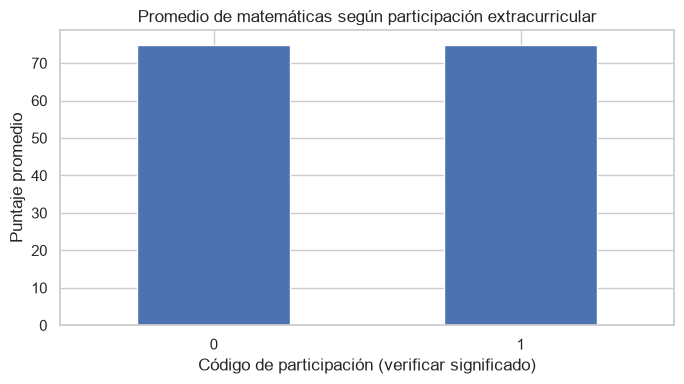

In [40]:
resumen_actividades = df.groupby("Extracurricular")["TestScore_Math"].agg(["count", "mean", "median", "std"])
display(resumen_actividades.rename(columns=estadisticas_es).rename_axis("Participación extracurricular").round(2))

resumen_actividades["mean"].plot(kind="bar", figsize=(7, 4))
plt.title("Promedio de matemáticas según participación extracurricular")
plt.xlabel("Código de participación (verificar significado)")
plt.ylabel("Puntaje promedio")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Estudio, asistencia y matemáticas
Los gráficos de dispersión permiten observar si hay una tendencia entre dos variables. Debe confirmarse la unidad de `StudyHours`: no asumimos que sean horas semanales. También hay que verificar la escala de asistencia.

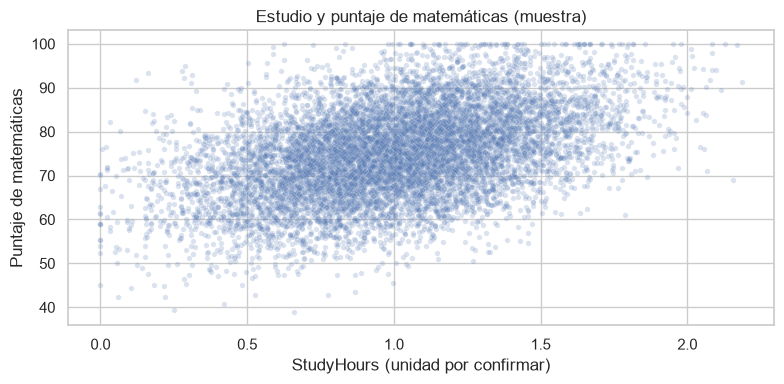

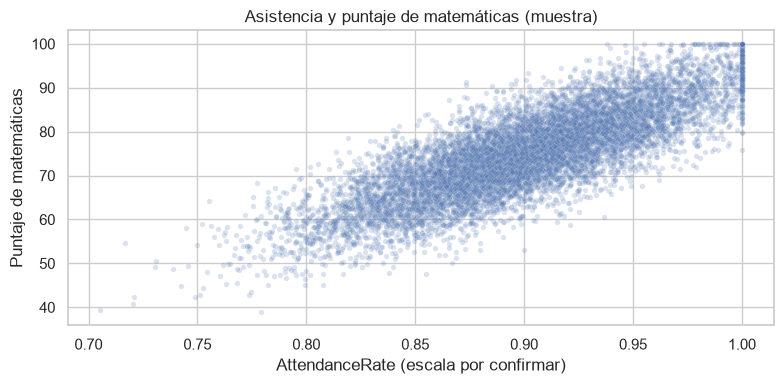

In [41]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=datos_graficos, x="StudyHours", y="TestScore_Math", alpha=0.2, s=15)
plt.title("Estudio y puntaje de matemáticas (muestra)")
plt.xlabel("StudyHours (unidad por confirmar)")
plt.ylabel("Puntaje de matemáticas")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.scatterplot(data=datos_graficos, x="AttendanceRate", y="TestScore_Math", alpha=0.2, s=15)
plt.title("Asistencia y puntaje de matemáticas (muestra)")
plt.xlabel("AttendanceRate (escala por confirmar)")
plt.ylabel("Puntaje de matemáticas")
plt.tight_layout()
plt.show()

## 12. Correlación entre variables numéricas
La correlación de Pearson resume la relación lineal entre variables: valores cercanos a 1 indican asociación positiva; cercanos a −1, negativa; cercanos a 0, poca asociación lineal. **Una correlación no demuestra causalidad.**

Elegimos variables numéricas de interés; no incluimos códigos de categorías como si fueran cantidades continuas.

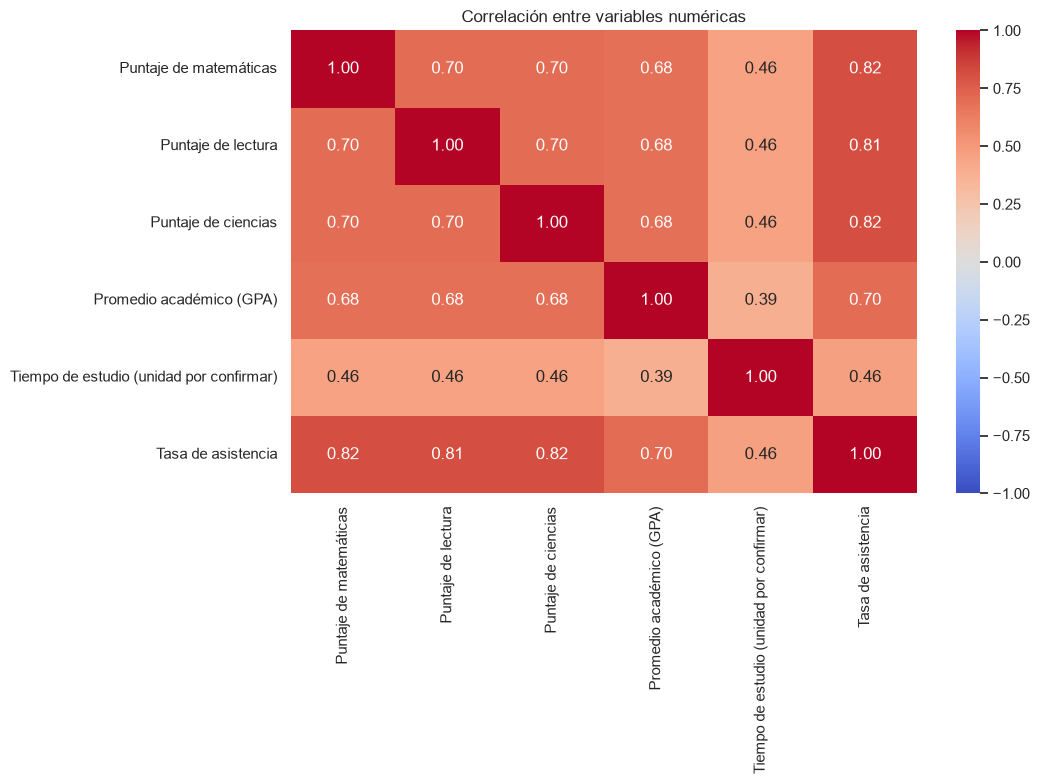

,Correlación con matemáticas
Tasa de asistencia,0.815
Puntaje de lectura,0.700
Puntaje de ciencias,0.700
Promedio académico (GPA),0.683
Tiempo de estudio (unidad por confirmar),0.456


Se ordena por la fuerza absoluta de la relación, no por importancia causal.


In [42]:
variables_numericas = [
    "TestScore_Math", "TestScore_Reading", "TestScore_Science",
    "GPA", "StudyHours", "AttendanceRate"
]

correlacion = df[variables_numericas].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(correlacion.rename(index=nombres_es, columns=nombres_es), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()
# Tabla ordenada para identificar las asociaciones lineales más marcadas.
asociaciones = correlacion["TestScore_Math"].drop("TestScore_Math")
asociaciones = asociaciones.reindex(asociaciones.abs().sort_values(ascending=False).index)
display(asociaciones.rename(index=nombres_es).to_frame("Correlación con matemáticas").round(3))
print("Se ordena por la fuerza absoluta de la relación, no por importancia causal.")

## 13. Variables para el futuro modelo
- **Variable dependiente:** `TestScore_Math`, el puntaje que se quiere predecir.
- **Posibles variables independientes:** edad, grado, contexto socioeconómico, educación parental, estudio, asistencia, internet, apoyo familiar y participación extracurricular.

La lista es inicial: hay que confirmar que estas variables estén disponibles antes de la evaluación de matemáticas. Lectura, ciencias y GPA se exploraron, pero no se incluyen por defecto como predictores porque podrían contener información del mismo período o del propio resultado que se quiere predecir.

Aquí no se hace imputación, codificación ni escalado para el modelo. Eso se realizará después de separar entrenamiento y test, ajustando las transformaciones solo con entrenamiento.

In [43]:
variable_dependiente = "TestScore_Math"

variables_independientes = [
    "Age", "Grade", "SES_Quartile", "ParentalEducation",
    "StudyHours", "AttendanceRate", "InternetAccess",
    "ParentSupport", "Extracurricular"
]

print("Variable dependiente:", nombres_es[variable_dependiente])
display(pd.DataFrame({"Posibles variables independientes": [nombres_es[c] for c in variables_independientes]}))

Variable dependiente: Puntaje de matemáticas


,Posibles variables independientes
0,Edad
1,Grado escolar
2,Cuartil socioeconómico
3,Educación de los padres
4,Tiempo de estudio (unidad por confirmar)
5,Tasa de asistencia
6,Acceso a internet
7,Apoyo parental
8,Participación extracurricular


## Resumen para apoyar la interpretación
Estas salidas se calculan al ejecutar con el CSV real. Muestran diferencias descriptivas entre grupos, no efectos causales. Una diferencia pequeña o grupos muy desiguales deben interpretarse con cuidado.

In [44]:
for nombre, tabla in [("Educación de los padres", resumen_padres),
                      ("Acceso a internet", resumen_internet),
                      ("Participación extracurricular", resumen_actividades)]:
    promedios = tabla["mean"].dropna()
    print("\n" + nombre)
    if len(promedios) >= 2:
        diferencia = promedios.max() - promedios.min()
        print("Mayor promedio observado:", promedios.idxmax(), "—", round(promedios.max(), 2))
        print("Menor promedio observado:", promedios.idxmin(), "—", round(promedios.min(), 2))
        print("Diferencia entre promedios extremos:", round(diferencia, 2), "puntos")
        print("Revisa también la cantidad de puntajes y su dispersión en la tabla anterior.")
    else:
        print("No hay al menos dos grupos con puntajes válidos para comparar.")


Educación de los padres
Mayor promedio observado: Bachelors+ — 74.99
Menor promedio observado: <HS — 74.95
Diferencia entre promedios extremos: 0.04 puntos
Revisa también la cantidad de puntajes y su dispersión en la tabla anterior.

Acceso a internet
Mayor promedio observado: 1 — 74.98
Menor promedio observado: 0 — 74.97
Diferencia entre promedios extremos: 0.01 puntos
Revisa también la cantidad de puntajes y su dispersión en la tabla anterior.

Participación extracurricular
Mayor promedio observado: 0 — 74.98
Menor promedio observado: 1 — 74.97
Diferencia entre promedios extremos: 0.0 puntos
Revisa también la cantidad de puntajes y su dispersión en la tabla anterior.


## 14. Conclusiones
**Completar estas observaciones después de ejecutar el notebook con el CSV real:**

1. **Calidad de datos:** indicar si se encontraron faltantes o filas repetidas y qué se necesita revisar.
2. **Rendimiento en matemáticas:** describir la concentración de los puntajes, su media y su dispersión.
3. **Factores relacionados:** señalar las diferencias observadas entre grupos y las tendencias de estudio y asistencia. Si no hay una relación clara, también debe indicarse.
4. **Aplicación:** proponer qué necesidades conviene investigar para orientar tutorías o apoyo académico, sin afirmar que una asociación demuestra una causa.

**Limitaciones:** no hay una variable que mida directamente el bienestar emocional. Los resultados describen el dataset analizado y no se pueden generalizar automáticamente a toda la institución.

### Alcance frente a la consigna
Este notebook cubre la carga del dataset, el análisis exploratorio y los gráficos, y una parte de la revisión y definición de variables de los puntos 1, 2 y 3. La preparación final, la separación de datos, el entrenamiento, la evaluación, las cinco predicciones y la automatización se realizarán en otro notebook.